# Initial-velocity MPS: six-panel figure

The figure measures 17.9 cm × 11.6 cm and contains only six line plots, a-f, without velocity maps or embedded tables. Panel labels use bold 9 pt text without parentheses; subplot titles are omitted.

The palette, pale marker fills, solid lines, thin axes, grid, and white rectangular legend frames follow `dense_sparse_consistency.pdf`. The panel-a legend uses the actual curves, with matching lines and markers. All plotting data come from the previous version; this notebook does not recompute velocity fields or MPS representations.


In [1]:
from pathlib import Path
import os
import json
import hashlib
import shutil

candidates = [Path.cwd(), Path.cwd() / 'output' / 'pdf' / 'mps_sixpanel_17p9cm']
if '__file__' in globals():
    candidates.insert(0, Path(__file__).resolve().parent)
ROOT = next((p for p in candidates if (p / 'data_manifest.json').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Run from the notebook folder containing data_manifest.json.')
DATA = ROOT / 'data'
CACHE = ROOT / '.cache'
CACHE.mkdir(exist_ok=True)
os.environ['MPLCONFIGDIR'] = str(CACHE / 'matplotlib')
os.environ.setdefault('TEXMFVAR', str(CACHE / 'texlive-var'))

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from matplotlib.lines import Line2D
from matplotlib.legend_handler import HandlerTuple

FIG_WIDTH_CM = 17.9
FIG_HEIGHT_CM = 11.6
FONTSIZE = 8
VELOCITY_COMPONENT = 'ux'  # 'ux', 'uy', or 'uz'; applies to panels a and b.
NS = [15, 18, 21, 24, 27]
EPSILONS = [1e-2, 1e-3, 1e-4]

# Four colors match dense_sparse_consistency.pdf exactly. Ochre extends
# the same muted palette to the fifth grid, with its own marker shape.
RED, PALE_RED = '#CE5044', '#FFE9F1'
BLUE, PALE_BLUE = '#7AA7D3', '#DDE9F5'
GREEN, PALE_GREEN = '#86B6A4', '#DFEDDC'
PURPLE, PALE_PURPLE = '#A486BE', '#EAE0F2'
OCHRE, PALE_OCHRE = '#D6A55B', '#F7E8D2'
N_COLORS = [RED, BLUE, GREEN, PURPLE, OCHRE]
N_FACES = [PALE_RED, PALE_BLUE, PALE_GREEN, PALE_PURPLE, PALE_OCHRE]
N_MARKERS = ['o', 's', '^', 'd', 'v']
EPS_COLORS = [BLUE, RED, GREEN]
EPS_FACES = [PALE_BLUE, PALE_RED, PALE_GREEN]
EPS_MARKERS = ['o', 's', '^']
USE_TEX = True
if USE_TEX and (shutil.which('latex') is None or shutil.which('dvipng') is None):
    raise RuntimeError('Install LaTeX and dvipng with bm, amsmath and sansmathfonts, or set USE_TEX=False for a font-approximate preview.')


In [2]:
LATEX_PREAMBLE = '\n    \\usepackage[T1]{fontenc}\n    \\usepackage{bm, amsmath, sansmathfonts}    \n\n    \\makeatletter\n    \\AtBeginDocument{\n        \\DeclareSymbolFont{sansextrabold}{T1}{cmss}{bx}{n}\n        \\DeclareMathSymbol{+}{\\mathbin}{sansextrabold}{"2B}\n        \\DeclareMathSymbol{=}{\\mathrel}{sansextrabold}{"3D}\n        \\DeclareMathSymbol{<}{\\mathrel}{sansextrabold}{"3C}\n        \\DeclareMathSymbol{>}{\\mathrel}{sansextrabold}{"3E}\n        \\DeclareMathSymbol{|}{\\mathord}{sansextrabold}{"7C}\n        \\DeclareMathSymbol{/}{\\mathord}{sansextrabold}{"2F}\n\n        \\DeclareSymbolFont{boldsanssymbols}{OMS}{cmsssy}{b}{n}\n        \\DeclareMathSymbol{-}{\\mathbin}{boldsanssymbols}{"00}\n        \\DeclareMathSymbol{\\times}{\\mathbin}{boldsanssymbols}{"02}\n\n\n        \\DeclareMathSymbol{\\oplus}{\\mathbin}{boldsanssymbols}{"08}\n        \\DeclareMathSymbol{\\otimes}{\\mathbin}{boldsanssymbols}{"0A}\n        \\DeclareMathSymbol{\\approx}{\\mathrel}{boldsanssymbols}{"19}\n        \\DeclareMathSymbol{\\perp}{\\mathrel}{boldsanssymbols}{"3F}\n        \\DeclareMathSymbol{\\sim}{\\mathrel}{boldsanssymbols}{"18}\n        \\DeclareMathSymbol{\\to}{\\mathrel}{boldsanssymbols}{"21}\n        \\DeclareMathSymbol{\\leftarrow}{\\mathrel}{boldsanssymbols}{"20}\n        \\DeclareMathSymbol{\\in}{\\mathrel}{boldsanssymbols}{"32}\n\n        \\let\\original@le\\le\n        \\let\\original@ge\\ge\n        \\let\\original@langle\\langle\n        \\let\\original@rangle\\rangle\n\n        \\renewcommand{\\le}{\\bm{\\original@le}}\n        \\renewcommand{\\ge}{\\bm{\\original@ge}}\n        \\renewcommand{\\langle}{\\bm{\\original@langle}}\n        \\renewcommand{\\rangle}{\\bm{\\original@rangle}}\n        \\renewcommand{\\|}{|\\hspace{-1pt}|}\n    }\n    \\makeatother\n\n    \\newcommand{\\p}{\\partial}\n    \\newcommand{\\T}{^{\\mathrm{T}}}\n    \\renewcommand{\\vec}[1]{\\boldsymbol{#1}}\n    \\newcommand{\\bn}{\\vec{\\nabla}}\n    \\newcommand\\ii{\\mathrm{i}}\n    \\newcommand\\ee{\\mathrm{e}}\n    \\newcommand{\\widebar}[1]{\\mskip.5\\thinmuskip\\overline{\\mskip-.5\\thinmuskip {#1} \\mskip-.5\\thinmuskip}\\mskip.5\\thinmuskip}\n    \\newcommand{\\ket}[1]{| #1 \\rangle}\n    \\newcommand{\\bra}[1]{\\langle #1 |}\n    '

# Sans-serif LaTeX text, thin axes, pale grid and filled markers follow
# the supplied dense/sparse consistency figure. No project import is required.
mpl.rcdefaults()
mpl.rcParams.update({
    'font.size': FONTSIZE, 'font.family': 'sans-serif',
    'text.usetex': USE_TEX, 'text.latex.preamble': LATEX_PREAMBLE,
    'figure.dpi': 150, 'savefig.dpi': 600,
    'pdf.fonttype': 42, 'ps.fonttype': 42,
    'axes.linewidth': 0.5, 'axes.labelsize': FONTSIZE,
    'xtick.labelsize': FONTSIZE, 'ytick.labelsize': FONTSIZE,
    'legend.fontsize': FONTSIZE, 'axes.unicode_minus': False,
    'lines.linewidth': 0.8, 'savefig.bbox': None, 'savefig.pad_inches': 0,
})

def cm_axes(fig, x, y, width, height):
    return fig.add_axes([x / FIG_WIDTH_CM, y / FIG_HEIGHT_CM,
                         width / FIG_WIDTH_CM, height / FIG_HEIGHT_CM])

def format_axis(ax):
    for spine in ax.spines.values():
        spine.set_linewidth(0.5)
    ax.tick_params(axis='x', which='major', direction='out', top=False,
                   length=3, width=0.5, pad=1.5)
    ax.tick_params(axis='y', which='major', direction='out', right=False,
                   length=3, width=0.5, pad=1)
    ax.tick_params(which='minor', direction='out', top=False, right=False,
                   length=1.5, width=0.5)
    ax.grid(color='k', linestyle='-', linewidth=0.5, alpha=0.1, which='major')
    ax.xaxis.labelpad = 1
    ax.yaxis.labelpad = 2
    ax.set_axisbelow(True)

panel_labels = {}

def panel_label(ax, letter):
    text = ax.text(-0.23, 1.045,
                   r'\textbf{' + letter + '}' if USE_TEX else letter,
                   transform=ax.transAxes, fontsize=9, fontweight='bold',
                   ha='left', va='bottom', gid='panel-' + letter)
    panel_labels[letter] = text
    return text

def threshold_label(epsilon):
    return rf'$\epsilon=10^{{{int(round(np.log10(epsilon)))}}}$'

def marker_curve(ax, x, y, color, face, marker, label=None, **kwargs):
    return ax.plot(x, y, color=color, lw=0.8, linestyle='-',
                   marker=marker, ms=4, markerfacecolor=face,
                   markeredgecolor=color, markeredgewidth=0.7,
                   label=label, **kwargs)[0]

legends = {}

def boxed_legend(ax, letter, **kwargs):
    options = dict(fontsize=8, frameon=True, fancybox=False, framealpha=0.9,
                   facecolor='white', edgecolor='#D0D0D0', borderpad=0.3,
                   labelspacing=0.25, handlelength=1.5, handletextpad=0.4,
                   borderaxespad=0.4, numpoints=1)
    options.update(kwargs)
    leg = ax.legend(**options)
    leg.get_frame().set_linewidth(0.5)
    legends[letter] = leg
    return leg


In [3]:
# Verify every plotting-data file before loading it.
manifest = json.loads((ROOT / 'data_manifest.json').read_text(encoding='utf-8'))
for relative, expected in manifest.items():
    actual = hashlib.sha256((ROOT / relative).read_bytes()).hexdigest()
    if actual != expected:
        raise RuntimeError(f'Plotting data checksum mismatch: {relative}')

spectra = np.load(DATA / 'schmidt_spectra.npz')
spectral_meta = pd.read_csv(DATA / 'schmidt_metadata.csv')
summary = pd.read_csv(DATA / 'mps_summary.csv')
bounds = pd.read_csv(DATA / 'upper_bounds_and_error_conventions.csv')
error_curves = pd.read_csv(DATA / 'unavoidable_error_curves.csv')
circuits = pd.read_csv(DATA / 'circuit_resources.csv')
audit = json.loads((DATA / 'audit_summary.json').read_text())
assert audit['passed']
assert len(spectral_meta) == 90 and len(summary) == 15

def rows_at_epsilon(frame, epsilon):
    return frame[np.isclose(frame['epsilon'], epsilon)].sort_values('n')

def component_rows(frame, n):
    return frame[(frame['n'] == n) & (frame['component'] == VELOCITY_COMPONENT)]

# Critical spectrum cut: maximize the 1% single-cut necessary rank for the
# selected velocity component; ties use the lowest cut index.
critical_cuts = {}
for n in NS:
    candidates = component_rows(spectral_meta, n).sort_values('cut')
    critical_cuts[n] = candidates.loc[candidates['rank_eps_1e_02'].idxmax()]
print('Verified local data. Critical spectrum cuts:',
      {n: int(row['cut']) for n, row in critical_cuts.items()})


Verified local data. Critical spectrum cuts: {15: 2, 18: 3, 21: 3, 24: 4, 27: 5}


## Panel contents

a: Schmidt spectra; b: scale-cut Schmidt entropy; c: rank requirements and necessary lower bounds; d: largest-grid error lower bound and measured reconstruction points; e: gauge-reduced parameter count; f: actual stored core scalars. Colors and markers match between a and b; error-tolerance colors and markers match across c, e, and f.


In [4]:
fig = plt.figure(figsize=(FIG_WIDTH_CM / 2.54, FIG_HEIGHT_CM / 2.54))
axes = {}
left_cm, right_cm, gap_cm = 1.35, 0.25, 1.55
axes_width_cm = (FIG_WIDTH_CM-left_cm-right_cm-2*gap_cm) / 3
axes_height_cm = 4.0
for letters, bottom_cm in [('abc', 7.0), ('def', 1.15)]:
    for column, letter in enumerate(letters):
        left = left_cm + column*(axes_width_cm+gap_cm)
        axes[letter] = cm_axes(fig, left, bottom_cm, axes_width_cm, axes_height_cm)
        format_axis(axes[letter])
        panel_label(axes[letter], letter)
component_symbol = VELOCITY_COMPONENT[-1]


In [5]:
# Panel a. One Line2D per spectrum includes both the line and sparse markers.
# The legend uses those actual artists, so color, fill and marker match exactly.
ax = axes['a']
spectrum_artists = []
for n, color, face, marker in zip(NS, N_COLORS, N_FACES, N_MARKERS):
    row = critical_cuts[n]
    values = spectra[row['key']] / np.sqrt(row['norm_squared'])
    ranks = np.arange(1, len(values)+1)
    selected = np.unique(np.geomspace(1, len(values), 9).astype(int)) - 1
    line, = ax.loglog(ranks, values, color=color, lw=0.8, linestyle='-',
                      marker=marker, markevery=selected.tolist(), ms=3.4,
                      mfc=face, mec=color, mew=0.7,
                      label=rf'$N={int(row["N"])},\ \ell={int(row["cut"])}$')
    spectrum_artists.append(line)
ax.set_xlim(0.9, 6000); ax.set_ylim(1e-8, 1)
ax.set_xlabel(r'Schmidt index, $j$')
ax.set_ylabel(r'$\sigma_j/\|u_' + component_symbol + r'\|_2$')
ax.xaxis.set_major_locator(ticker.LogLocator(base=10, numticks=5))
ax.yaxis.set_major_locator(ticker.LogLocator(base=10, numticks=5))
ax.xaxis.set_minor_formatter(ticker.NullFormatter())
ax.yaxis.set_minor_formatter(ticker.NullFormatter())
boxed_legend(ax, 'a', loc='lower left')

# Panel b. Entropy colors and markers match panel a.
ax = axes['b']
for n, color, face, marker in zip(NS, N_COLORS, N_FACES, N_MARKERS):
    rows = component_rows(spectral_meta, n).sort_values('cut')
    marker_curve(ax, rows['cut']/rows['L'], rows['entropy_bits'], color, face, marker)
ell = np.arange(1, 9)
ax.plot(ell/9, 3*np.minimum(ell, 9-ell), color='0.65', lw=0.7, ls=':', zorder=0)
ax.text(0.5, 11.6, r'$n=27$ upper bound', color='0.4', fontsize=7,
        ha='center', va='top')
ax.set_xlim(0, 1); ax.set_ylim(0, 13)
ax.set_xticks([0, 0.5, 1]); ax.set_yticks([0, 4, 8, 12])
ax.set_xlabel(r'Scale cut, $\ell/L$'); ax.set_ylabel(r'$S_\ell$ (bits)')

# Panel c. Verified constructions and necessary rank bounds.
ax = axes['c']
for epsilon, color, face, marker in zip(EPSILONS, EPS_COLORS, EPS_FACES, EPS_MARKERS):
    rows = rows_at_epsilon(bounds, epsilon)
    y = rows['constructed_fraction_of_maximum'].to_numpy()
    lower = rows['necessary_fraction_of_maximum'].to_numpy()
    marker_curve(ax, rows['n'], y, color, face, marker, label=threshold_label(epsilon))
    ax.errorbar(rows['n'], y, yerr=np.vstack((y-lower, np.zeros(len(y)))),
                fmt='none', color=color, elinewidth=0.7, capsize=2, capthick=0.7)
ax.axhline(1, color='0.4', lw=0.6, ls=':')
ax.set_xticks(NS); ax.set_xlim(14, 28); ax.set_ylim(0, 1.07)
ax.set_yticks([0, 0.5, 1])
ax.set_xlabel(r'Spatial qubits, $n$'); ax.set_ylabel(r'$\chi/\chi_{\max}$')
boxed_legend(ax, 'c', loc='lower left')


In [6]:
# Panel d. Lower bound on largest-grid reconstruction error.
ax = axes['d']
curve = error_curves[error_curves['n'] == 27].sort_values('chi')
bound_line, = ax.semilogy(curve['chi'],
                          np.maximum(curve['necessary_maximum_component_error'], 1e-16),
                          color=BLUE, lw=0.9, label='Schmidt lower bound')
verification_handles = []
for epsilon, color, face, marker in zip(EPSILONS, EPS_COLORS, EPS_FACES, EPS_MARKERS):
    row = rows_at_epsilon(summary, epsilon).query('n == 27').iloc[0]
    ax.axhline(epsilon, color=color, ls=':', lw=0.6)
    if row['maximum_component_relative_error'] >= 5e-5:
        point, = ax.semilogy(row['chi_achieved_max'], row['maximum_component_relative_error'],
                             linestyle='none', marker=marker, ms=4,
                             mfc=face, mec=color, mew=0.7)
        verification_handles.append(point)
ax.set_xlim(0, 4240); ax.set_ylim(5e-5, 1)
ax.set_xticks([0, 1024, 2048, 3072, 4096])
ax.set_yticks([1e-4, 1e-2, 1])
ax.yaxis.set_minor_formatter(ticker.NullFormatter())
ax.set_xlabel(r'Bond cap, $\chi$'); ax.set_ylabel(r'Relative $L^2$ error')
boxed_legend(ax, 'd', loc='center left', bbox_to_anchor=(0.02, 0.42), fontsize=7.1,
              handles=[bound_line, tuple(verification_handles)],
              labels=['Schmidt lower bound', 'Verified MPS'],
              handler_map={tuple: HandlerTuple(ndivide=None, pad=0.25)})
ax.text(0.06, 0.17, r'$\chi=4096$' + '\n' + r'$\mathcal{E}<1.2\times10^{-14}$',
        transform=ax.transAxes, fontsize=7.1, ha='left', va='bottom')

# Panels e and f. Parameter count and stored core scalars.
for letter, column, ylabel, limits in [
    ('e', 'gauge_reduced_parameter_ratio_to_dense', r'$P_{\mathrm{NVPS}}/(3N^3)$', (0, 1.07)),
    ('f', 'stored_parameter_ratio_to_dense', r'$P_{\mathrm{store}}/(3N^3)$', (0, 2.2)),
]:
    ax = axes[letter]
    for epsilon, color, face, marker in zip(EPSILONS, EPS_COLORS, EPS_FACES, EPS_MARKERS):
        rows = rows_at_epsilon(summary, epsilon)
        marker_curve(ax, rows['n'], rows[column], color, face, marker,
                     label=threshold_label(epsilon))
    ax.axhline(1, color='0.4', lw=0.6, ls=':')
    ax.set_xticks(NS); ax.set_xlim(14, 28); ax.set_ylim(*limits)
    ax.set_xlabel(r'Spatial qubits, $n$'); ax.set_ylabel(ylabel)
    ax.set_yticks([0, 0.5, 1] if letter == 'e' else [0, 1, 2])
    boxed_legend(ax, letter, loc='lower left')


In [7]:
FIGURE_CAPTION = 'Matrix product state (MPS) representations of geometrically generated initial velocity fields on $N^3$ grids, with $n=3\\log_2N$ spatial qubits.\n\\textbf{a} Normalized Schmidt spectra of $u_x$ at the cuts requiring the largest single-cut rank for a relative $L^2$ error of $10^{-2}$. Lines and markers identify the grid size and cut, as indicated in the legend.\n\\textbf{b} Schmidt entropy $S_\\ell$ at the relative scale cut $\\ell/L$, where $L=\\log_2N$. Colors and markers match \\textbf{a}; the gray dotted line gives the entropy bound for $n=27$.\n\\textbf{c} Verified MPS bond dimensions normalized by the octal-encoding bound $\\chi_{\\max}=8^{\\lfloor L/2\\rfloor}$. Downward bars extend to the necessary ranks inferred from the Schmidt spectra and do not represent statistical uncertainty.\n\\textbf{d} Schmidt lower bound on the maximum componentwise relative $L^2$ error for the $512^3$ grid as a function of the bond cap $\\chi$. Symbols give measured MPS reconstruction errors; colored horizontal lines mark the target errors.\n\\textbf{e,f} Gauge-reduced parameter counts and stored MPS scalars, respectively, normalized by the dense velocity representation with $3N^3$ real scalars. The horizontal reference in \\textbf{c}, \\textbf{e}, and \\textbf{f} marks unity.\nEach grid uses one realization. The population fractions of the first spinor component are $0.5$, $0.5$, $0.08$, $0.02$, and $0.006$ for increasing $N$.'
MPS_CAPTION = 'Resources of the velocity MPS at a componentwise relative $L^2$ error tolerance $\\epsilon=10^{-2}$.\nThe spatial register contains $n$ qubits and represents an $N^3$ grid.\nThe octal scale encoding has $L=\\log_2N$ sites and the rank bound $\\chi_{\\max}=8^{\\lfloor L/2\\rfloor}$.\nThe necessary bound $\\chi_{\\mathrm{lb}}$ follows from the Schmidt spectra, whereas $\\chi_{\\mathrm{built}}$ is attained by an explicitly constructed MPS with verified reconstruction error.\nBoth ranks are maxima over all cuts and velocity components.\n$P_{\\mathrm{NVPS}}$ excludes internal gauge freedom.\nParameter counts and storage sum the three velocity components.\nStorage uses double precision, with $1\\,\\mathrm{MiB}=2^{20}$ bytes.\nEach row represents one realization with the manuscript parameters.'
CIRCUIT_CAPTION = 'Resources of the generating spinor circuits.\nThe qubit count gives the spatial register size of each component circuit.\nThe parameter count includes shared amplitude angles, independent phase angles for both spinor components, and one population fraction.\nGate counts are summed over the two circuits, and the reported depth is their maximum.\nTranspilation uses the $\\{U,\\mathrm{CX}\\}$ basis at optimization level 3 without a hardware coupling constraint.\nThese counts cover spinor preparation before Gray decoding and Fourier transforms.\nThey exclude velocity evaluation, measurement, and time evolution.'

FIGURE_CAPTION = FIGURE_CAPTION.replace('u_x', 'u_' + component_symbol)
# The two tables are exported separately and are not drawn into the figure.
(ROOT / 'figure_caption.tex').write_text(
    r'\caption{' + FIGURE_CAPTION + '}\n' +
    r'\label{fig:velocity_mps_resources}' + '\n', encoding='utf-8')
figure_include = [
    r'\begin{figure*}[t]', r'\centering',
    r'\includegraphics[width=17.9cm]{mps_sixpanel_17p9cm.pdf}',
    r'\input{figure_caption.tex}', r'\end{figure*}', '',
]
(ROOT / 'figure_include.tex').write_text('\n'.join(figure_include), encoding='utf-8')

mps_tex = [
    r'\begin{table*}[t]', r'\centering',
    r'\caption{' + MPS_CAPTION + '}',
    r'\label{tab:velocity_mps_resources}',
    r'\begin{tabular}{rrrrrrr}', r'\hline\hline',
    r'$n$ & $N$ & $\chi_{\max}$ & $\chi_{\mathrm{lb}}$ & $\chi_{\mathrm{built}}$ & $P_{\mathrm{NVPS}}/(3N^3)$ & Storage (MiB) \\',
    r'\hline',
]
for _, row in rows_at_epsilon(summary, 1e-2).iterrows():
    values = [
        str(int(row['n'])), str(int(row['grid'])),
        str(int(row['maximum_possible_chi'])), str(int(row['chi_lower_bound_max'])),
        str(int(row['chi_achieved_max'])),
        f"{row['gauge_reduced_parameter_ratio_to_dense']:.4f}",
        f"{row['mps_core_bytes']/2**20:.2f}",
    ]
    mps_tex.append(' & '.join(values) + r' \\')
mps_tex.extend([r'\hline\hline', r'\end{tabular}', r'\end{table*}', ''])
(ROOT / 'table_mps.tex').write_text('\n'.join(mps_tex), encoding='utf-8')

circuit_tex = [
    r'\begin{table}[t]', r'\centering',
    r'\caption{' + CIRCUIT_CAPTION + '}',
    r'\label{tab:spinor_circuit_resources}',
    r'\begin{tabular}{rrrrr}', r'\hline\hline',
    r'Qubits & Parameters & \shortstack{CX\\gates} & \shortstack{$U$\\gates} & \shortstack{Max.\\depth} \\',
    r'\hline',
]
for _, row in circuits.sort_values('n').iterrows():
    values = [str(int(row[key])) for key in [
        'n', 'generative_scalar_parameters', 'pre_transform_cx_gates_both_components',
        'pre_transform_u_gates_both_components', 'pre_transform_depth_max']]
    circuit_tex.append(' & '.join(values) + r' \\')
circuit_tex.extend([r'\hline\hline', r'\end{tabular}', r'\end{table}', ''])
(ROOT / 'table_circuit.tex').write_text('\n'.join(circuit_tex), encoding='utf-8')

(ROOT / 'captions.md').write_text(
    '# Figure caption\n\n' + FIGURE_CAPTION +
    '\n\n# Table 1 caption\n\n' + MPS_CAPTION +
    '\n\n# Table 2 caption\n\n' + CIRCUIT_CAPTION + '\n', encoding='utf-8')
assert 'can be' not in (FIGURE_CAPTION + MPS_CAPTION + CIRCUIT_CAPTION).lower()
print('Exported the figure caption and two separate LaTeX tables with captions.')


Exported the figure caption and two separate LaTeX tables with captions.


Exported mps_sixpanel_17p9cm.pdf; figure size 17.9 x 11.6 cm.


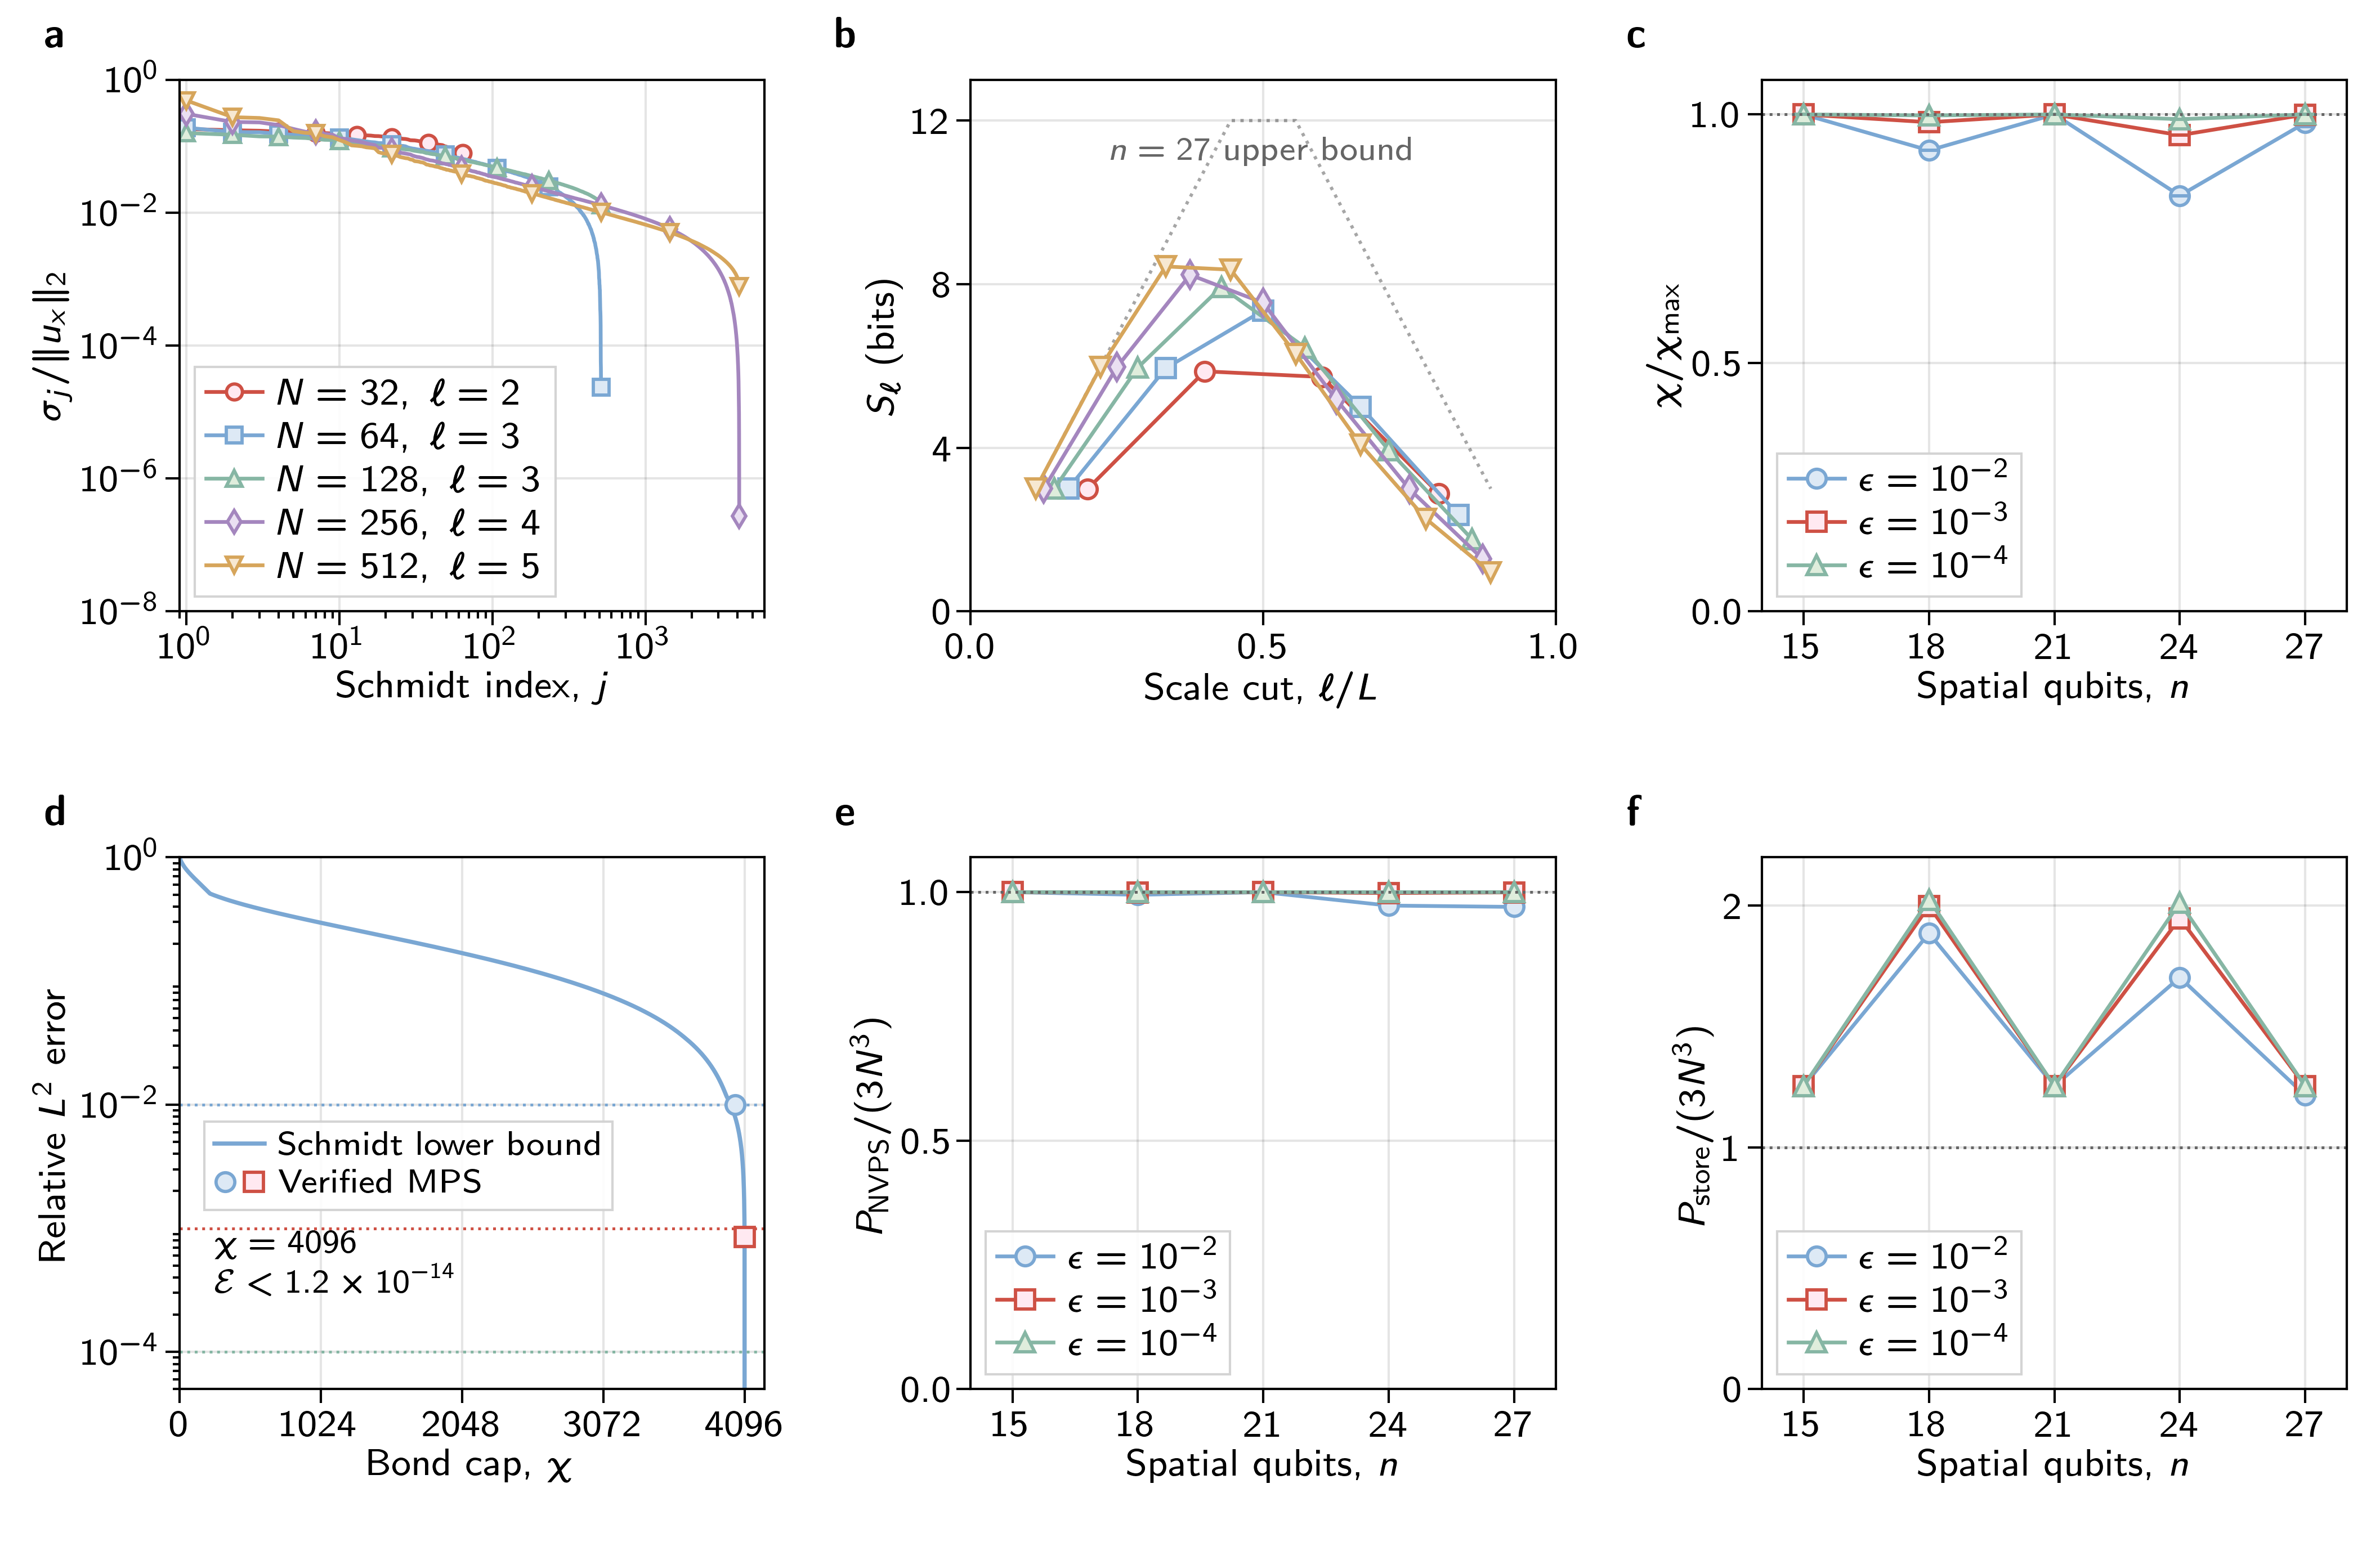

In [8]:
assert set(panel_labels) == set('abcdef')
assert len(axes) == 6 and len(fig.axes) == 6
assert all(abs(text.get_fontsize()-9) < 1e-12 for text in panel_labels.values())
assert all(text.get_fontweight() == 'bold' for text in panel_labels.values())
assert all(not ax.get_title() for ax in fig.axes)
assert all(', $' in ax.get_xlabel() for ax in axes.values())
assert all(leg.get_frame_on() for leg in legends.values())

# Verify the actual panel-a legend artists against their corresponding curves.
legend_a = legends['a'].legend_handles
for source, handle in zip(spectrum_artists, legend_a):
    for getter in ('get_marker', 'get_linestyle', 'get_color',
                   'get_markerfacecolor', 'get_markeredgecolor'):
        assert getattr(source, getter)() == getattr(handle, getter)(), getter
    assert handle.get_marker() not in ('', 'None', 'none', None)

fig.canvas.draw()
renderer = fig.canvas.get_renderer()
axes_boxes = {}
legend_boxes = {}
for letter, ax in axes.items():
    box = ax.get_tightbbox(renderer).transformed(fig.transFigure.inverted())
    assert box.x0 >= 0 and box.y0 >= 0 and box.x1 <= 1 and box.y1 <= 1, (letter, box)
    axes_boxes[letter] = list(box.bounds)
for letter, leg in legends.items():
    box = leg.get_window_extent(renderer)
    assert axes[letter].bbox.contains(box.x0, box.y0)
    assert axes[letter].bbox.contains(box.x1, box.y1)
    legend_boxes[letter] = list(box.transformed(fig.transFigure.inverted()).bounds)

layout_record = {
    'width_cm': FIG_WIDTH_CM, 'height_cm': FIG_HEIGHT_CM,
    'line_panels': 6, 'velocity_cloud_panels': 0, 'tables_in_figure': 0,
    'panel_labels': {letter: {'text': text.get_text(),
                             'fontsize_pt': text.get_fontsize(),
                             'fontweight': text.get_fontweight()}
                     for letter, text in panel_labels.items()},
    'axes_titles': [ax.get_title() for ax in fig.axes],
    'xlabels': {letter: ax.get_xlabel() for letter, ax in axes.items()},
    'legends_boxed': True, 'panel_a_legend_matches_line_and_marker': True,
    'axes_tight_boxes': axes_boxes, 'legend_boxes': legend_boxes,
    'reference_palette': [RED, BLUE, GREEN, PURPLE],
    'fifth_grid_palette_extension': OCHRE,
}
(ROOT / 'layout_validation.json').write_text(json.dumps(layout_record, indent=2), encoding='utf-8')

# No tight cropping: the exported PDF retains the exact 17.9 cm width.
pdf_path = ROOT / 'mps_sixpanel_17p9cm.pdf'
png_path = ROOT / 'mps_sixpanel_17p9cm.png'
fig.savefig(pdf_path, format='pdf', bbox_inches=None, pad_inches=0,
            facecolor='white', transparent=False,
            metadata={'Title': 'Velocity-field MPS resource comparison',
                      'Subject': 'Six panels a-f; 17.9 cm width; separate LaTeX tables',
                      'Creator': 'Self-contained Matplotlib notebook'})
fig.savefig(png_path, format='png', dpi=600, bbox_inches=None, pad_inches=0,
            facecolor='white', transparent=False)
assert abs(fig.get_figwidth()*2.54-FIG_WIDTH_CM) < 1e-12
assert abs(fig.get_figheight()*2.54-FIG_HEIGHT_CM) < 1e-12
print(f'Exported {pdf_path.name}; figure size {FIG_WIDTH_CM:.1f} x {FIG_HEIGHT_CM:.1f} cm.')
if mpl.get_backend().lower() != 'agg':
    plt.show()


## Reuse

Run all cells or execute the Python script in this directory to export the PDF, PNG, updated caption, and two separate LaTeX tables. Preserve the relative locations of `data/` and `data_manifest.json`. The 30-qubit row appears only in the circuit table and uses compilation statistics; all six line plots use the original 15-27-qubit velocity-field data.
